# MC833 · Projeto 3 — Parte 2: Modelamento preditivo com LSTM

**Previsão de tráfego de rede com redes neurais recorrentes** · comparando a Internet de **2007** e de **2024**

## Contexto
Na parte de EDA você conheceu o throughput dos dois traces MAWI (sábado, 10/02, 14:00 JST, em 2007 e em 2024). Agora você vai **treinar uma LSTM para prever o throughput do próximo segundo** a partir dos segundos anteriores, e **comparar os modelos dos dois anos**.

## Como funciona
* **Entrada:** uma janela deslizante com os últimos `look_back` valores do throughput (ex.: 10 s).
* **Saída:** o valor previsto para o segundo seguinte.
* **Rede:** uma camada **LSTM** + uma camada **densa** (arquitetura enxuta).
* **Treino/teste:** primeiros 80% do tempo para treino, últimos 20% para teste (sem embaralhar).
* **Métrica:** **MSE** (erro quadrático médio). Mostramos também o RMSE em Mbps e o RMSE relativo à média, que permite comparar 2007 e 2024.

## O que você vai entregar (seção "Modelamento preditivo" do relatório)
| Item do relatório | Onde |
|---|---|
| Descrição da abordagem LSTM (arquitetura, hiperparâmetros, divisão treino/teste, normalização) | Tarefa T1 + exemplo E2 |
| Gráfico **real × previsto** no conjunto de teste | T1 e T2 |
| Tabela de **MSE** por janela (10, 20 e 30) | T2 |
| Modelo de cada ano **salvo** | T2 |
| **Comparação 2007 × 2024**: matriz modelo × teste e gráficos | T3 |
| Análise: onde o modelo acerta e erra, e o que a comparação mostra | Seção 5 |

## Como usar este notebook
* Rode as células **em ordem**. Os **exemplos** (E1 e E2) já estão prontos.
* Complete as células marcadas com `# TODO` nas **tarefas** T1–T3. O **bônus** (B1) é opcional.
* **Fixe as sementes** (`fixar_sementes`) e **comente seu código**.
* Dica: no Colab, use *Ambiente de execução → Alterar tipo → GPU* se quiser acelerar, mas as séries são pequenas e a CPU basta.
* Salve as figuras do relatório com `plt.savefig('nome.png', dpi=200, bbox_inches='tight')` antes de `plt.show()`.

## 1. Setup

In [3]:
import os, sys, json, random, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'           # menos mensagens do TensorFlow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow import keras

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')                 # silencia avisos repetitivos do TensorFlow
EM_COLAB = 'google.colab' in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

# ============================ CONFIGURAÇÃO ============================
PASTA_DADOS = '/content/drive/MyDrive/MC833A_T3_2026/dados'      # pasta com uma subpasta por trace (a mesma da parte de EDA)
TRACES = {'2007': '200702101400', '2024': '202402101400'}
PASTA_MODELOS = 'modelos'      # onde salvar os modelos treinados (crie sua própria pasta)

ESCALA_MS = 1000               # granularidade da série: 1 ponto por segundo (tente 100 para mais pontos)
FRAC_TREINO = 0.8              # 80% do tempo para treino, 20% para teste (divisão temporal, sem embaralhar)
SEMENTE = 42                   # reprodutibilidade
# ======================================================================
os.makedirs(PASTA_MODELOS, exist_ok=True)
print('TensorFlow', tf.__version__, '| Keras', keras.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow 2.21.0 | Keras 3.13.2


### Funções auxiliares e carga dos dados
Não precisa alterá-las; leia os comentários.

In [11]:
import shutil, os
dest = '/content/drive/MyDrive/MC833A_T3_2026/entrega'
os.makedirs(dest, exist_ok=True)
for f in ['lstm_2007_t1.png', 'lstm_melhor_real_previsto.png', 'matriz_modelo_teste.png']:
    if os.path.exists(f):
        shutil.copy(f, dest)
if os.path.isdir('modelos'):
    shutil.copytree('modelos', f'{dest}/modelos', dirs_exist_ok=True)

In [4]:
# ---------- Estilo: cor do ano = cor do MODELO treinado naquele ano; a série real é sempre cinza ----------
COR = {'2007': '#2a78d6', '2024': '#eb6834'}
COR_REAL = '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'legend.frameon': False, 'legend.fontsize': 9, 'lines.linewidth': 1.2})

# ---------- Dados: a série de throughput (Mbps) de cada ano ----------
def carregar_serie(ano, escala_ms=ESCALA_MS):
    """Lê a série fina (10 ms) do ano e soma em intervalos de `escala_ms`. Devolve o throughput em Mbps
    como pd.Series indexada pelo tempo (s). (O último intervalo, se incompleto, é descartado.)"""
    tid = TRACES[ano]
    df = pd.read_parquet(os.path.join(PASTA_DADOS, tid, f'{tid}_serie_10ms.parquet'), columns=['bytes'])
    fator = escala_ms // 10
    n = (len(df) // fator) * fator
    soma = df['bytes'].values[:n].reshape(-1, fator).sum(axis=1)
    return pd.Series(soma * 8 / (escala_ms / 1000) / 1e6, index=np.arange(len(soma)) * escala_ms / 1000, name='Mbps')

SERIES = {ano: carregar_serie(ano) for ano in TRACES}
for ano, s in SERIES.items():
    print(f'{ano}: {len(s)} pontos | média {s.mean():.1f} Mbps | mín {s.min():.1f} | máx {s.max():.1f}')

# ---------- Reprodutibilidade ----------
def fixar_sementes(semente=SEMENTE):
    random.seed(semente); np.random.seed(semente); keras.utils.set_random_seed(semente)

# ---------- Janelas deslizantes ----------
def create_sequences(data, look_back):
    """data: array (n, 1). Devolve X (n-look_back, look_back, 1) e y (n-look_back, 1):
    cada amostra usa `look_back` valores seguidos para prever o valor seguinte."""
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:i + look_back])
        y.append(data[i + look_back])
    return np.array(X), np.array(y)

# ---------- Métricas ----------
def metricas(real, prev):
    """MSE e RMSE em Mbps (unidades reais) e RMSE relativo à média da série real (permite comparar 2007 e 2024)."""
    real, prev = np.asarray(real), np.asarray(prev)
    mse = float(np.mean((real - prev) ** 2))
    return {'MSE (Mbps²)': mse, 'RMSE (Mbps)': mse ** 0.5, 'RMSE/média (%)': 100 * mse ** 0.5 / float(np.mean(real))}

# ---------- Gráfico real × previsto ----------
def plotar_real_previsto(ax, t, real, prev, cor, titulo, rotulo_prev='prevista'):
    """Curva real (cinza) × curva prevista (cor do modelo) no conjunto de teste."""
    ax.plot(t, real, color=COR_REAL, lw=1.3, label='real')
    ax.plot(t, prev, color=cor, lw=1.3, label=rotulo_prev)
    ax.set_title(titulo); ax.set_xlabel('tempo (s)'); ax.set_ylabel('Mbps'); ax.legend()

2007: 900 pontos | média 94.3 Mbps | mín 66.6 | máx 123.7
2024: 899 pontos | média 1229.1 Mbps | mín 483.0 | máx 5591.1


## 2. Exemplos resolvidos

### Exemplo E1 · A série e a divisão treino/teste

**Objetivo:** Ver a série de throughput (1 ponto por segundo) de cada ano e onde ela é dividida em **treino (80%)** e **teste (20%)**. A divisão é **temporal**: o teste é sempre o final da série, o "futuro" que o modelo nunca viu.

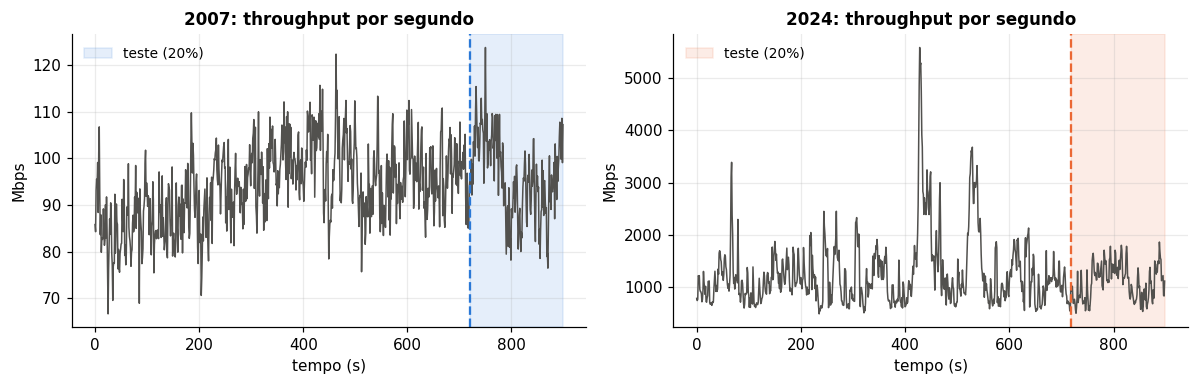

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, ano in zip(axs, SERIES):
    s = SERIES[ano]; corte = s.index[int(len(s) * FRAC_TREINO)]
    ax.plot(s.index, s.values, color=COR_REAL, lw=1)
    ax.axvline(corte, color=COR[ano], lw=1.5, ls='--')
    ax.axvspan(corte, s.index[-1], color=COR[ano], alpha=0.12, label='teste (20%)')
    ax.set_title(f'{ano}: throughput por segundo'); ax.set_xlabel('tempo (s)'); ax.set_ylabel('Mbps'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

### Exemplo E2 · Preparação: normalização e janelas deslizantes

**Objetivo:** Transformar a série em exemplos de treino: cada **janela** de `look_back` valores seguidos (entrada `X`) deve prever o valor seguinte (alvo `y`). Leia com atenção os comentários: eles explicam por que o *scaler* é ajustado só no treino. A função `preparar_dados` será usada em todas as tarefas.

In [6]:
def preparar_dados(serie, look_back, frac_treino=FRAC_TREINO, scaler=None):
    """Prepara a série para a LSTM:
       1) separa os primeiros `frac_treino` (treino) dos últimos (teste), **sem embaralhar** (é uma série temporal);
       2) normaliza para [0, 1] com MinMaxScaler ajustado **só no treino** (se ajustasse na série toda, o teste
          "vazaria" informação para o treino); se `scaler` for dado, ele é reutilizado em vez de ajustado;
       3) cria as janelas deslizantes de tamanho `look_back`.
       Cada alvo de teste é um instante do conjunto de teste; sua janela de entrada olha só para o passado
       (as primeiras janelas de teste usam os últimos pontos do treino)."""
    valores = serie.values.reshape(-1, 1)
    n_treino = int(len(valores) * frac_treino)
    if scaler is None:
        scaler = MinMaxScaler().fit(valores[:n_treino])
    esc = scaler.transform(valores)
    X, y = create_sequences(esc, look_back)
    posicao_alvo = np.arange(look_back, len(esc))              # instante (índice) de cada alvo y
    tr, te = posicao_alvo < n_treino, posicao_alvo >= n_treino
    return dict(X_tr=X[tr], y_tr=y[tr], X_te=X[te], y_te=y[te], scaler=scaler,
                t_te=serie.index.values[posicao_alvo[te]], n_treino=n_treino)

def prever(modelo, d):
    """Previsões do modelo no conjunto de teste, de volta à escala real (Mbps). Devolve (real, previsto)."""
    prev = d['scaler'].inverse_transform(modelo.predict(d['X_te'], verbose=0)).ravel()
    real = d['scaler'].inverse_transform(d['y_te']).ravel()
    return real, prev

def persistencia(d):
    """Baseline sem aprendizado: prever que o próximo valor é igual ao último valor observado."""
    return d['scaler'].inverse_transform(d['X_te'][:, -1, :]).ravel()

# Demonstração com a série de 2007 e janela de 10 passos
d = preparar_dados(SERIES['2007'], look_back=10)
print('X_tr:', d['X_tr'].shape, '| y_tr:', d['y_tr'].shape, '| X_te:', d['X_te'].shape, '| y_te:', d['y_te'].shape)
print(f"treino = primeiros {d['n_treino']} pontos; escala do scaler (treino): "
      f"{float(d['scaler'].data_min_[0]):.1f} a {float(d['scaler'].data_max_[0]):.1f} Mbps")

X_tr: (710, 10, 1) | y_tr: (710, 1) | X_te: (180, 10, 1) | y_te: (180, 1)
treino = primeiros 720 pontos; escala do scaler (treino): 66.6 a 122.3 Mbps


## 3. Tarefas

### Tarefa T1 · A LSTM: construir, treinar e avaliar (2007, janela de 10)

**Objetivo:** Implementar a arquitetura **enxuta**: **uma camada LSTM + uma camada densa** que prevê o próximo ponto. Treinar com os dados de treino de **2007** (janela de 10 s) e avaliar no teste com o **MSE**. Plotar **real × previsto** e a **curva de perda**.

**Dados:** `preparar_dados(SERIES["2007"], look_back=10)` (exemplo E2), `prever(modelo, d)`, `metricas(real, prev)` e `plotar_real_previsto(...)`.

**Dicas:**

* `keras.Sequential([keras.layers.Input(shape=(look_back, 1)), keras.layers.LSTM(32), keras.layers.Dense(1)])`.
* `modelo.compile(optimizer="adam", loss="mse")`.
* `modelo.fit(X_tr, y_tr, epochs=..., batch_size=..., validation_split=0.1, callbacks=[EarlyStopping(...)], verbose=0)`: o `validation_split` reserva o final do treino para validação, e o `EarlyStopping` (com `restore_best_weights=True`) para quando a validação para de melhorar.
* Chame `fixar_sementes(SEMENTE)` antes de treinar, para o resultado ser reproduzível.
* Registre os hiperparâmetros usados (`epochs`, `batch_size`, nº de unidades): vão para o relatório.

LSTM: {'MSE (Mbps²)': 40.667318721856525, 'RMSE (Mbps)': 6.377093281570885, 'RMSE/média (%)': 6.6340040302809475}
Persistência: {'MSE (Mbps²)': 38.17910349559253, 'RMSE (Mbps)': 6.178924137387716, 'RMSE/média (%)': 6.427851345485245}


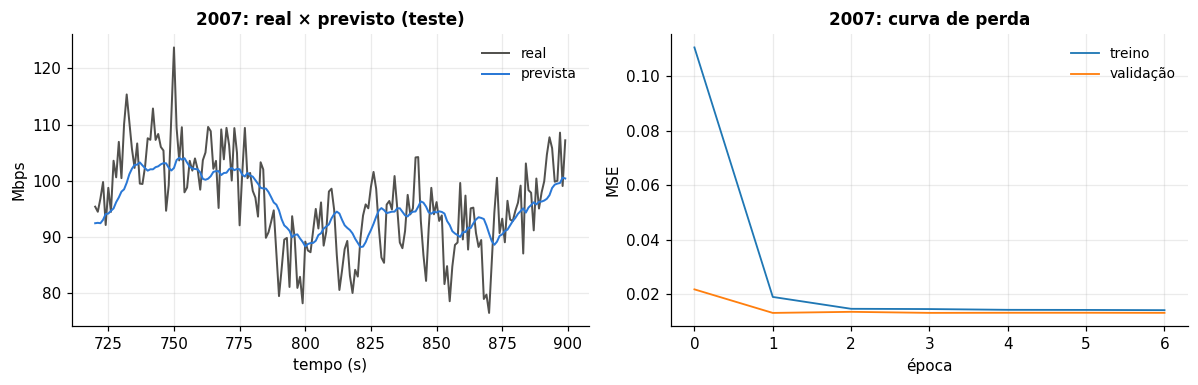

In [7]:
def construir_modelo(look_back, unidades=32):
    """Arquitetura enxuta: uma camada LSTM seguida de uma camada densa (saída: o próximo ponto)."""
    modelo = keras.Sequential([
        keras.layers.Input(shape=(look_back, 1)),
        keras.layers.LSTM(unidades),
        keras.layers.Dense(1),
    ])
    modelo.compile(optimizer='adam', loss='mse')
    return modelo

def treinar(dados, look_back, epochs=50, batch_size=32, unidades=32):
    """Treina uma LSTM nos dados de treino. Devolve (modelo, historico)."""
    modelo = construir_modelo(look_back, unidades)
    parar = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True)
    hist = modelo.fit(
        dados['X_tr'], dados['y_tr'],
        epochs=epochs, batch_size=batch_size,
        validation_split=0.1, callbacks=[parar], verbose=0)
    return modelo, hist

LOOK_BACK, EPOCHS, BATCH_SIZE = 10, 50, 32

fixar_sementes(SEMENTE)
d07 = preparar_dados(SERIES['2007'], LOOK_BACK)
modelo07, hist07 = treinar(d07, LOOK_BACK, EPOCHS, BATCH_SIZE)
real, prev = prever(modelo07, d07)
print('LSTM:', metricas(real, prev))
print('Persistência:', metricas(real, persistencia(d07)))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
plotar_real_previsto(axs[0], d07['t_te'], real, prev, COR['2007'], '2007: real × previsto (teste)')
axs[1].plot(hist07.history['loss'], label='treino')
axs[1].plot(hist07.history['val_loss'], label='validação')
axs[1].set_title('2007: curva de perda')
axs[1].set_xlabel('época')
axs[1].set_ylabel('MSE')
axs[1].legend()
plt.tight_layout()
plt.savefig('lstm_2007_t1.png', dpi=200, bbox_inches='tight')
plt.show()

### Tarefa T2 · Sensibilidade à janela (look-back): 10, 20 e 30

**Objetivo:** Repetir o treino para **janelas de 10, 20 e 30 passos**, em **2007 e 2024**, e montar uma **tabela de MSE** por configuração. Escolher a melhor janela de cada ano e **salvar o melhor modelo**.

**Dados:** `preparar_dados`, `treinar`, `prever`, `metricas` e `persistencia` (E2 e T1).

**Dicas:**

* Use dois `for` (ano, janela) e guarde o que precisar de cada treino num dicionário `RESULTADOS[(ano, janela)]` (modelo, dados, real, previsto): você vai reaproveitá-lo na T3.
* Escolha a melhor janela pela **perda de validação** (`min(hist.history["val_loss"])`), não pelo teste: o teste só serve para o resultado final.
* Salve com `modelo.save(f"{PASTA_MODELOS}/lstm_{ano}.keras")`.
* Compare sempre com a persistência: se a LSTM não ganha dela, isso também é um resultado.
* Para ir além: varie também `epochs` e `batch_size`.

val_loss mín.  MSE (Mbps²)  RMSE (Mbps)  RMSE/média LSTM (%)  \
ano  janela (s)                                                                 
2007 10                 0.0132      40.6673       6.3771               6.6340   
     20                 0.0105      32.2908       5.6825               5.9114   
     30                 0.0106      32.7187       5.7200               5.9505   
2024 10                 0.0030   66760.6568     258.3808              23.5790   
     20                 0.0019   42095.4818     205.1718              18.7233   
     30                 0.0015   39277.5436     198.1856              18.0858   

                 RMSE/média persist. (%)  
ano  janela (s)                           
2007 10                           6.4279  
     20                           6.4279  
     30                           6.4279  
2024 10                          18.5900  
     20                          18.5900  
     30                          18.5900

2007: melhor janela = 20 s (menor val_loss)
2024: melhor janela = 30 s (menor val_loss)


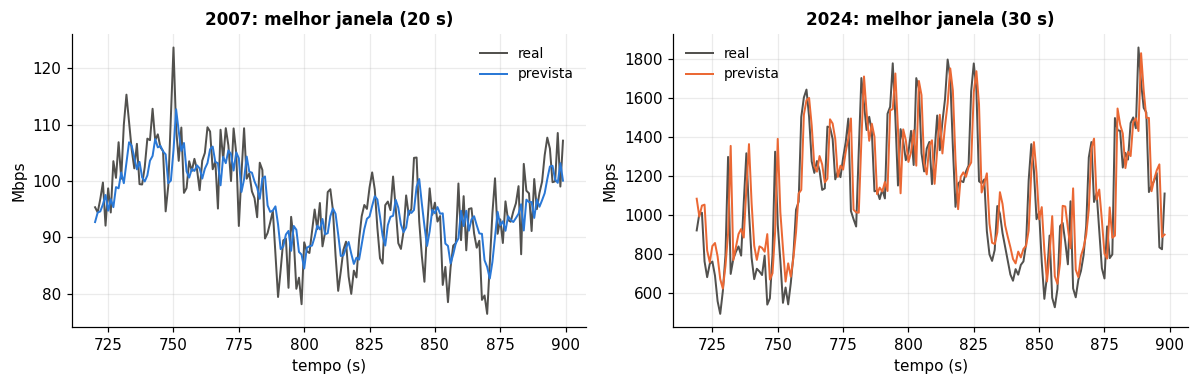

In [8]:
JANELAS = [10, 20, 30]
RESULTADOS = {}                    # (ano, janela) -> modelo, dados, real, previsto, val_loss_min

linhas_tabela = []
for ano in TRACES:
    for janela in JANELAS:
        fixar_sementes(SEMENTE)
        dados = preparar_dados(SERIES[ano], janela)
        modelo, hist = treinar(dados, janela, EPOCHS, BATCH_SIZE)
        real, prev = prever(modelo, dados)
        val_min = min(hist.history['val_loss'])
        m_lstm = metricas(real, prev)
        m_pers = metricas(real, persistencia(dados))
        RESULTADOS[(ano, janela)] = {
            'modelo': modelo, 'dados': dados, 'hist': hist,
            'real': real, 'prev': prev, 'val_loss_min': val_min,
        }
        linhas_tabela.append({
            'ano': ano, 'janela (s)': janela,
            'val_loss mín.': val_min,
            'MSE (Mbps²)': m_lstm['MSE (Mbps²)'],
            'RMSE (Mbps)': m_lstm['RMSE (Mbps)'],
            'RMSE/média LSTM (%)': m_lstm['RMSE/média (%)'],
            'RMSE/média persist. (%)': m_pers['RMSE/média (%)'],
        })

tabela_janelas = pd.DataFrame(linhas_tabela).set_index(['ano', 'janela (s)'])
display(tabela_janelas.round(4))

MELHOR = {
    ano: min(JANELAS, key=lambda j: RESULTADOS[(ano, j)]['val_loss_min'])
    for ano in TRACES
}
for ano, janela in MELHOR.items():
    RESULTADOS[(ano, janela)]['modelo'].save(f'{PASTA_MODELOS}/lstm_{ano}.keras')
    print(f'{ano}: melhor janela = {janela} s (menor val_loss)')

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, ano in zip(axs, TRACES):
    j = MELHOR[ano]
    r = RESULTADOS[(ano, j)]
    plotar_real_previsto(ax, r['dados']['t_te'], r['real'], r['prev'], COR[ano],
                         f'{ano}: melhor janela ({j} s)')
plt.tight_layout()
plt.savefig('lstm_melhor_real_previsto.png', dpi=200, bbox_inches='tight')
plt.show()

### Tarefa T3 · Comparando 2007 e 2024: o modelo de um ano prevê o outro?

**Objetivo:** Montar a **matriz 2×2**: modelo treinado em {2007, 2024} × testado em {2007, 2024}. As diagonais são os testes "normais"; as **fora da diagonal** testam se o que a LSTM aprendeu num ano vale no outro. Use o **mesmo scaler do ano de treino** do modelo (o modelo só conhece aquela escala).

**Dados:** `RESULTADOS` e `MELHOR` (T2) e `preparar_dados(serie, look_back, scaler=...)`, que reutiliza um scaler já ajustado.

**Dicas:**

* Para testar o modelo treinado em `ano_tr` na série de `ano_te`: `d = preparar_dados(SERIES[ano_te], janela, scaler=RESULTADOS[(ano_tr, janela)]["dados"]["scaler"])` e depois `prever(modelo, d)`.
* Use a **janela escolhida para o ano de treino** (`MELHOR[ano_tr]`).
* Compare as células pela coluna **RMSE/média (%)**: o MSE em Mbps² não é comparável entre anos de escalas tão diferentes.
* Para o gráfico, use uma grade 2×2 (linhas = modelo, colunas = ano de teste), com `plotar_real_previsto`.

,modelo,teste,MSE (Mbps²),RMSE (Mbps),RMSE/média (%),RMSE/média persist. (%)
0,2007,2007,32.2908,5.6825,5.9114,6.4279
1,2007,2024,878531.7406,937.3002,85.5349,18.5900
2,2024,2007,91807.4482,302.9974,315.2041,6.4279
3,2024,2024,39277.5436,198.1856,18.0858,18.5900


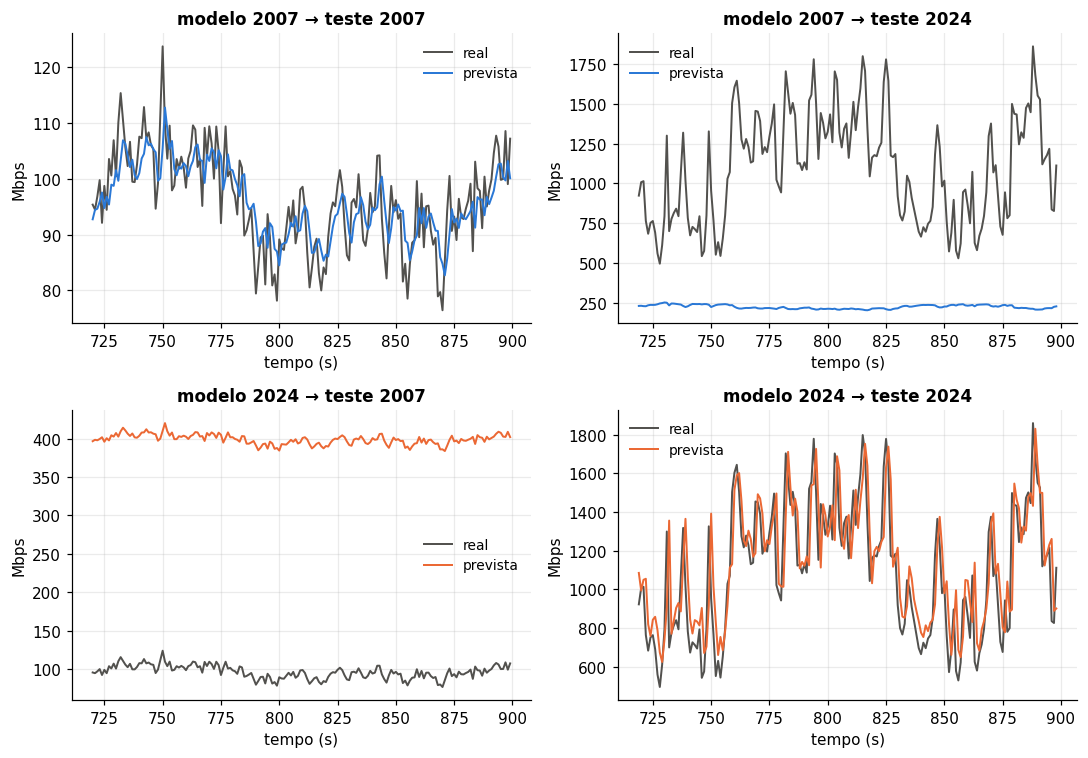

In [9]:
ANOS = ['2007', '2024']

linhas_matriz = []
for ano_tr in ANOS:
    for ano_te in ANOS:
        janela = MELHOR[ano_tr]
        ref = RESULTADOS[(ano_tr, janela)]
        scaler_tr = ref['dados']['scaler']
        dados_te = preparar_dados(SERIES[ano_te], janela, scaler=scaler_tr)
        real, prev = prever(ref['modelo'], dados_te)
        m = metricas(real, prev)
        m_pers = metricas(real, persistencia(dados_te))
        linhas_matriz.append({
            'modelo': ano_tr, 'teste': ano_te,
            'MSE (Mbps²)': m['MSE (Mbps²)'],
            'RMSE (Mbps)': m['RMSE (Mbps)'],
            'RMSE/média (%)': m['RMSE/média (%)'],
            'RMSE/média persist. (%)': m_pers['RMSE/média (%)'],
        })

df_matriz = pd.DataFrame(linhas_matriz)
display(df_matriz.round(4))

fig, axs = plt.subplots(2, 2, figsize=(10, 7))
for i, ano_tr in enumerate(ANOS):
    for j, ano_te in enumerate(ANOS):
        janela = MELHOR[ano_tr]
        ref = RESULTADOS[(ano_tr, janela)]
        scaler_tr = ref['dados']['scaler']
        dados_te = preparar_dados(SERIES[ano_te], janela, scaler=scaler_tr)
        real, prev = prever(ref['modelo'], dados_te)
        plotar_real_previsto(
            axs[i, j], dados_te['t_te'], real, prev, COR[ano_tr],
            f'modelo {ano_tr} → teste {ano_te}')
plt.tight_layout()
plt.savefig('matriz_modelo_teste.png', dpi=200, bbox_inches='tight')
plt.show()